# 01 — Data Collection: Sentinel-1 → LULC dataset

**Goal:** build a semantic segmentation dataset where the *only* model input is Sentinel-1 SAR, and labels come from ESA WorldCover 2021.

| Item | Choice |
|---|---|
| Input | Sentinel-1 GRD, IW mode, VV + VH, monthly median composite → bands `VV`, `VH`, `VV−VH` (dB) |
| Preprocessing (by ESA/GEE) | orbit file, border + thermal noise removal, radiometric calibration (σ⁰), terrain correction (SRTM 30 m), dB conversion |
| Preprocessing (ours) | 3×3 focal-median speckle filter in linear power, temporal median per month, VV−VH ratio |
| Labels | ESA WorldCover v200 (2021), 10 m, remapped to 6 SAR-separable classes |
| Months | Jan, Apr, Jul, Oct 2021 (one per season, all paired with the same 2021 label) |
| Regions | 21 × 15.36 km squares across Europe, split **by region** into train / val / test |
| Patches | 256 × 256 px at 10 m, exact UTM grid (labels and SAR on the identical grid) |
| Storage | `int16` (dB × 100) for SAR, `uint8` for labels, plus `metadata.csv` |

Mannheim/Heidelberg is **not** in the dataset — it is reserved for the prototype case study.

**Folder layout expected:** `project/s1lulc/` (the module) and `project/notebooks/01_data_collection.ipynb` (this file). Data is written to `project/data/`.

In [1]:
%pip install -q earthengine-api pyproj numpy pandas matplotlib tqdm


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm
import ee

ROOT = Path.cwd().parent if (Path.cwd().parent / "s1lulc").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))
from s1lulc import config as C, gee

DATA_DIR = ROOT / "data" / "patches"; DATA_DIR.mkdir(parents=True, exist_ok=True)
CMAP = ListedColormap(C.PALETTE)
print("Project root:", ROOT)

/home/jovyan/vault/DL_proj/project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /home/jovyan/vault/DL_proj/project


## 1. Connect to Google Earth Engine
Put your Google Cloud project ID below (the one registered for Earth Engine). The first run prints a link: open it, sign in, and paste the code back.

In [3]:
GEE_PROJECT = os.environ.get("GEE_PROJECT", "your-gee-project-id")   # set in terminal: export GEE_PROJECT=...
gee.init(GEE_PROJECT)
print("Earth Engine OK:", ee.String("hello").getInfo())

Earth Engine OK: hello


## 2. Regions and splits

In [4]:
regions = pd.DataFrame([{"region": k, "lat": v[0], "lon": v[1], "split": v[2]} for k, v in C.REGIONS.items()])
print(regions.split.value_counts().to_string())
regions

split
train    15
val       3
test      3


,region,lat,lon,split
0,munich,48.14,11.58,train
1,lyon,45.76,4.84,train
2,milan,45.46,9.19,train
3,warsaw,52.23,21.01,train
4,seville,37.39,-5.98,train
5,amsterdam,52.37,4.90,train
6,bucharest,44.43,26.10,train
7,black_forest,48.00,8.20,train
8,beauce_cropland,48.30,1.70,train
9,hungarian_plain,47.00,20.20,train


## 3. Sentinel-1 availability (scenes per region and month)
For the report: how many acquisitions go into each monthly median.

In [5]:
rows = []
for _, r in tqdm(regions.iterrows(), total=len(regions)):
    _, _, _, geom = gee.region_grid(r.lat, r.lon)
    for m in C.TRAIN_MONTHS:
        rows.append({"region": r.region, "month": m, "scenes": gee.scene_count(geom, C.LABEL_YEAR, m)})
scenes = pd.DataFrame(rows).pivot(index="region", columns="month", values="scenes")
scenes.to_csv(ROOT / "data" / "scene_counts.csv")
scenes

  0%|          | 0/21 [00:00<?, ?it/s]

  5%|▍         | 1/21 [00:01<00:38,  1.93s/it]

 10%|▉         | 2/21 [00:03<00:29,  1.58s/it]

 14%|█▍        | 3/21 [00:05<00:31,  1.75s/it]

 19%|█▉        | 4/21 [00:07<00:33,  1.98s/it]

 24%|██▍       | 5/21 [00:08<00:28,  1.76s/it]

... (14 outputs left out)

 95%|█████████▌| 20/21 [00:26<00:01,  1.08s/it]

100%|██████████| 21/21 [00:27<00:00,  1.07s/it]

100%|██████████| 21/21 [00:27<00:00,  1.29s/it]

month,1,4,7,10
region,,,,
almeria,19,17,19,18
amsterdam,20,20,20,21
bavarian_forest,12,14,16,16
beauce_cropland,30,30,29,30
black_forest,22,22,22,22
bucharest,20,20,19,22
camargue_wetland,21,23,21,23
hungarian_plain,27,28,29,28
jutland_cropland,27,25,21,26


## 4. Test one patch
Check that SAR and label line up before downloading everything.

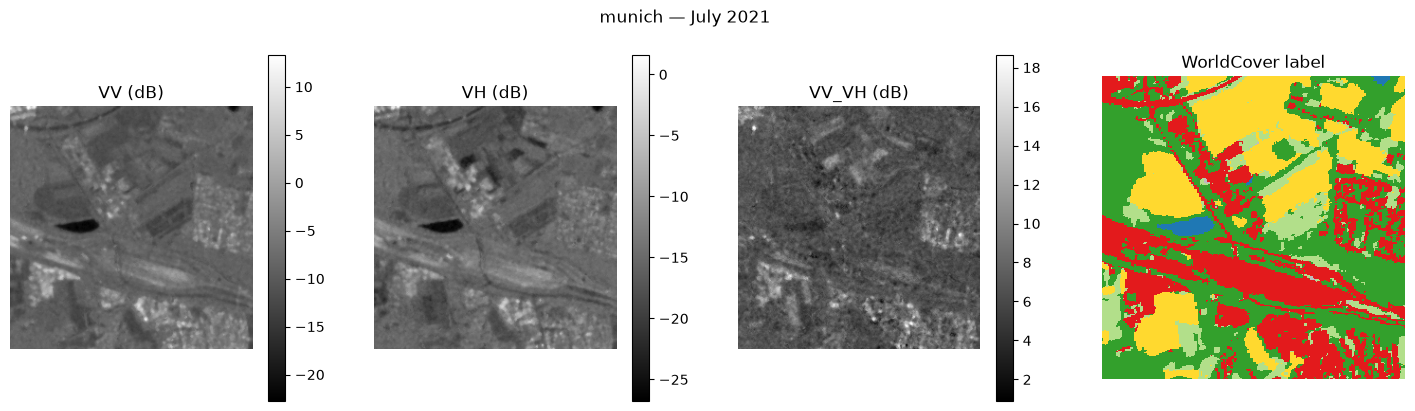

In [6]:
r = regions.iloc[0]
epsg, x0, y0, geom = gee.region_grid(r.lat, r.lon)
s1 = gee.fetch(gee.monthly_composite(geom, C.LABEL_YEAR, 7), epsg, x0, y0)
lab = gee.fetch(gee.worldcover_label(), epsg, x0, y0)[0]

fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
for i, name in enumerate(C.S1_BANDS):
    im = ax[i].imshow(s1[i], cmap="gray"); ax[i].set_title(f"{name} (dB)"); plt.colorbar(im, ax=ax[i])
ax[3].imshow(lab, cmap=CMAP, vmin=0, vmax=C.NUM_CLASSES - 1, interpolation="nearest"); ax[3].set_title("WorldCover label")
for a in ax: a.axis("off")
plt.suptitle(f"{r.region} — July {C.LABEL_YEAR}"); plt.show()

## 5. Download all patches
Each region is split into 6 × 6 patches. Per patch: 1 label + 4 monthly SAR composites (~3,800 downloads, roughly 15–30 min).
Already-downloaded files are skipped, so re-run this cell if it gets interrupted.

In [7]:
label_img = gee.worldcover_label()

def jobs():
    for _, r in regions.iterrows():
        epsg, X0, Y0, geom = gee.region_grid(r.lat, r.lon)
        comps = {m: gee.monthly_composite(geom, C.LABEL_YEAR, m) for m in C.TRAIN_MONTHS}
        step = C.PATCH_SIZE * C.SCALE
        for i in range(C.PATCHES_PER_SIDE):
            for j in range(C.PATCHES_PER_SIDE):
                x0, y0 = X0 + j * step, Y0 - i * step
                pid = f"{r.region}_{i}_{j}"
                yield ("label", pid, None, label_img, epsg, x0, y0)
                for m, img in comps.items():
                    yield ("s1", pid, m, img, epsg, x0, y0)

def run(job, retries=4):
    kind, pid, m, img, epsg, x0, y0 = job
    path = DATA_DIR / (f"{pid}_label.npy" if kind == "label" else f"{pid}_m{m:02d}.npy")
    if path.exists():
        return path
    err = None
    for k in range(retries):
        try:
            arr = gee.fetch(img, epsg, x0, y0)
            if kind == "label":
                np.save(path, arr[0].astype(np.uint8))
            else:
                np.save(path, np.clip(arr * C.INT16_SCALE, -32768, 32767).astype(np.int16))
            return path
        except Exception as e:
            err = e; time.sleep(2 ** k)
    print("FAILED", path.name, err)

all_jobs = list(jobs())
print(len(all_jobs), "downloads")
with ThreadPoolExecutor(max_workers=8) as ex:
    for _ in tqdm(as_completed([ex.submit(run, j) for j in all_jobs]), total=len(all_jobs)):
        pass

3780 downloads


  0%|          | 0/3780 [00:00<?, ?it/s]

  0%|          | 1/3780 [00:00<16:39,  3.78it/s]

  0%|          | 2/3780 [00:00<19:35,  3.21it/s]

  0%|          | 3/3780 [00:01<40:54,  1.54it/s]

  0%|          | 4/3780 [00:01<29:26,  2.14it/s]

... (2,659 outputs left out)

100%|█████████▉| 3778/3780 [15:18<00:00,  3.24it/s]

100%|█████████▉| 3779/3780 [15:21<00:00,  1.22it/s]

100%|██████████| 3780/3780 [15:29<00:00,  2.72s/it]

100%|██████████| 3780/3780 [15:29<00:00,  4.07it/s]

## 6. Quality filter + metadata
A patch-month is kept if ≤ 5 % of SAR pixels are missing and ≤ 20 % of label pixels are ignored (snow / no data).

In [8]:
rows = []
for _, r in regions.iterrows():
    for i in range(C.PATCHES_PER_SIDE):
        for j in range(C.PATCHES_PER_SIDE):
            pid = f"{r.region}_{i}_{j}"
            lp = DATA_DIR / f"{pid}_label.npy"
            if not lp.exists(): continue
            lab = np.load(lp)
            ignored = float((lab == C.IGNORE_INDEX).mean())
            counts = np.bincount(lab[lab != C.IGNORE_INDEX].ravel(), minlength=C.NUM_CLASSES)[:C.NUM_CLASSES]
            for m in C.TRAIN_MONTHS:
                sp = DATA_DIR / f"{pid}_m{m:02d}.npy"
                if not sp.exists(): continue
                s1 = np.load(sp)
                missing = float((s1[0] <= C.S1_NODATA * C.INT16_SCALE + 1).mean())
                rows.append({"patch": pid, "region": r.region, "split": r.split, "month": m,
                             "s1_path": sp.name, "label_path": lp.name,
                             "s1_missing": missing, "label_ignored": ignored,
                             **{f"px_{c}": int(n) for c, n in zip(C.CLASSES, counts)}})
meta = pd.DataFrame(rows)
meta["keep"] = (meta.s1_missing <= 0.05) & (meta.label_ignored <= 0.20)
meta.to_csv(ROOT / "data" / "metadata.csv", index=False)
meta.groupby("split").keep.agg(["sum", "count"])

,sum,count
split,,
test,432,432
train,2160,2160
val,432,432


## 7. Class distribution per split (for the report)

,Water,Built-up,Tree cover,Cropland,Grass/Shrub/Wetland,Bare/Sparse
split,,,,,,
test,5.5,29.4,28.8,21.8,14.0,0.4
train,10.3,23.1,26.4,15.5,23.7,1.0
val,6.3,22.7,41.3,10.6,18.2,0.9


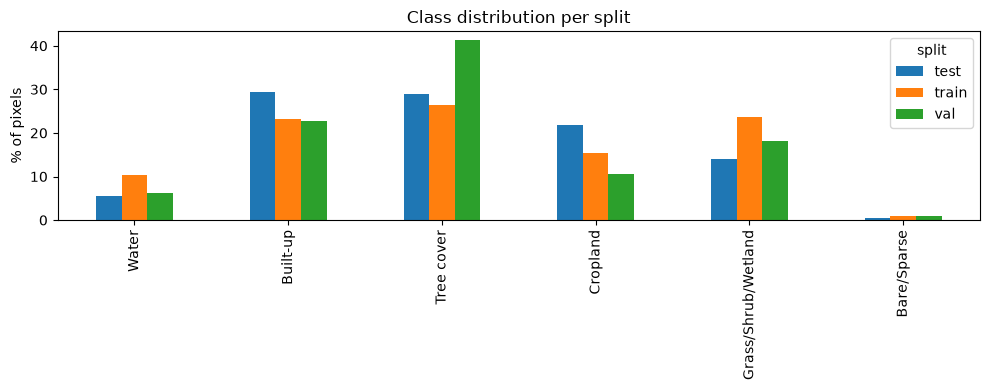

{'Water': np.float64(0.44),
 'Built-up': np.float64(0.19),
 'Tree cover': np.float64(0.17),
 'Cropland': np.float64(0.29),
 'Grass/Shrub/Wetland': np.float64(0.19),
 'Bare/Sparse': np.float64(4.72)}

In [9]:
kept = meta[meta.keep].drop_duplicates("patch")   # label is identical for all months of a patch
px = kept.groupby("split")[[f"px_{c}" for c in C.CLASSES]].sum()
px.columns = C.CLASSES
pct = (px.T / px.sum(axis=1)).T * 100
display(pct.round(1))
pct.T.plot.bar(figsize=(10, 4)); plt.ylabel("% of pixels")
plt.title("Class distribution per split"); plt.tight_layout()
plt.savefig(ROOT / "data" / "class_distribution.png", dpi=150); plt.show()

# inverse-frequency class weights from the training split (used in the loss later)
tr = px.loc["train"].values.astype(float)
weights = tr.sum() / (C.NUM_CLASSES * np.maximum(tr, 1)); weights = weights / weights.mean()
json.dump(dict(zip(C.CLASSES, weights.round(4).tolist())), open(ROOT / "data" / "class_weights.json", "w"), indent=2)
dict(zip(C.CLASSES, weights.round(2)))

## 8. Normalisation statistics (training split only)

In [10]:
tr_meta = meta[(meta.split == "train") & meta.keep]
sample = tr_meta.sample(min(400, len(tr_meta)), random_state=0)
vals = np.stack([np.load(DATA_DIR / p).astype(np.float32) / C.INT16_SCALE for p in sample.s1_path])
vals = vals.transpose(1, 0, 2, 3).reshape(3, -1)
vals = vals[:, vals[0] > C.S1_NODATA + 1]
stats = {"bands": C.S1_BANDS, "mean": vals.mean(1).tolist(), "std": vals.std(1).tolist()}
json.dump(stats, open(ROOT / "data" / "norm_stats.json", "w"), indent=2)
stats

{'bands': ['VV', 'VH', 'VV_VH'],
 'mean': [-10.301989555358887, -17.580530166625977, 6.560324668884277],
 'std': [4.438543319702148, 4.555870056152344, 2.0471389293670654]}

## 9. Visual check: random patches across seasons

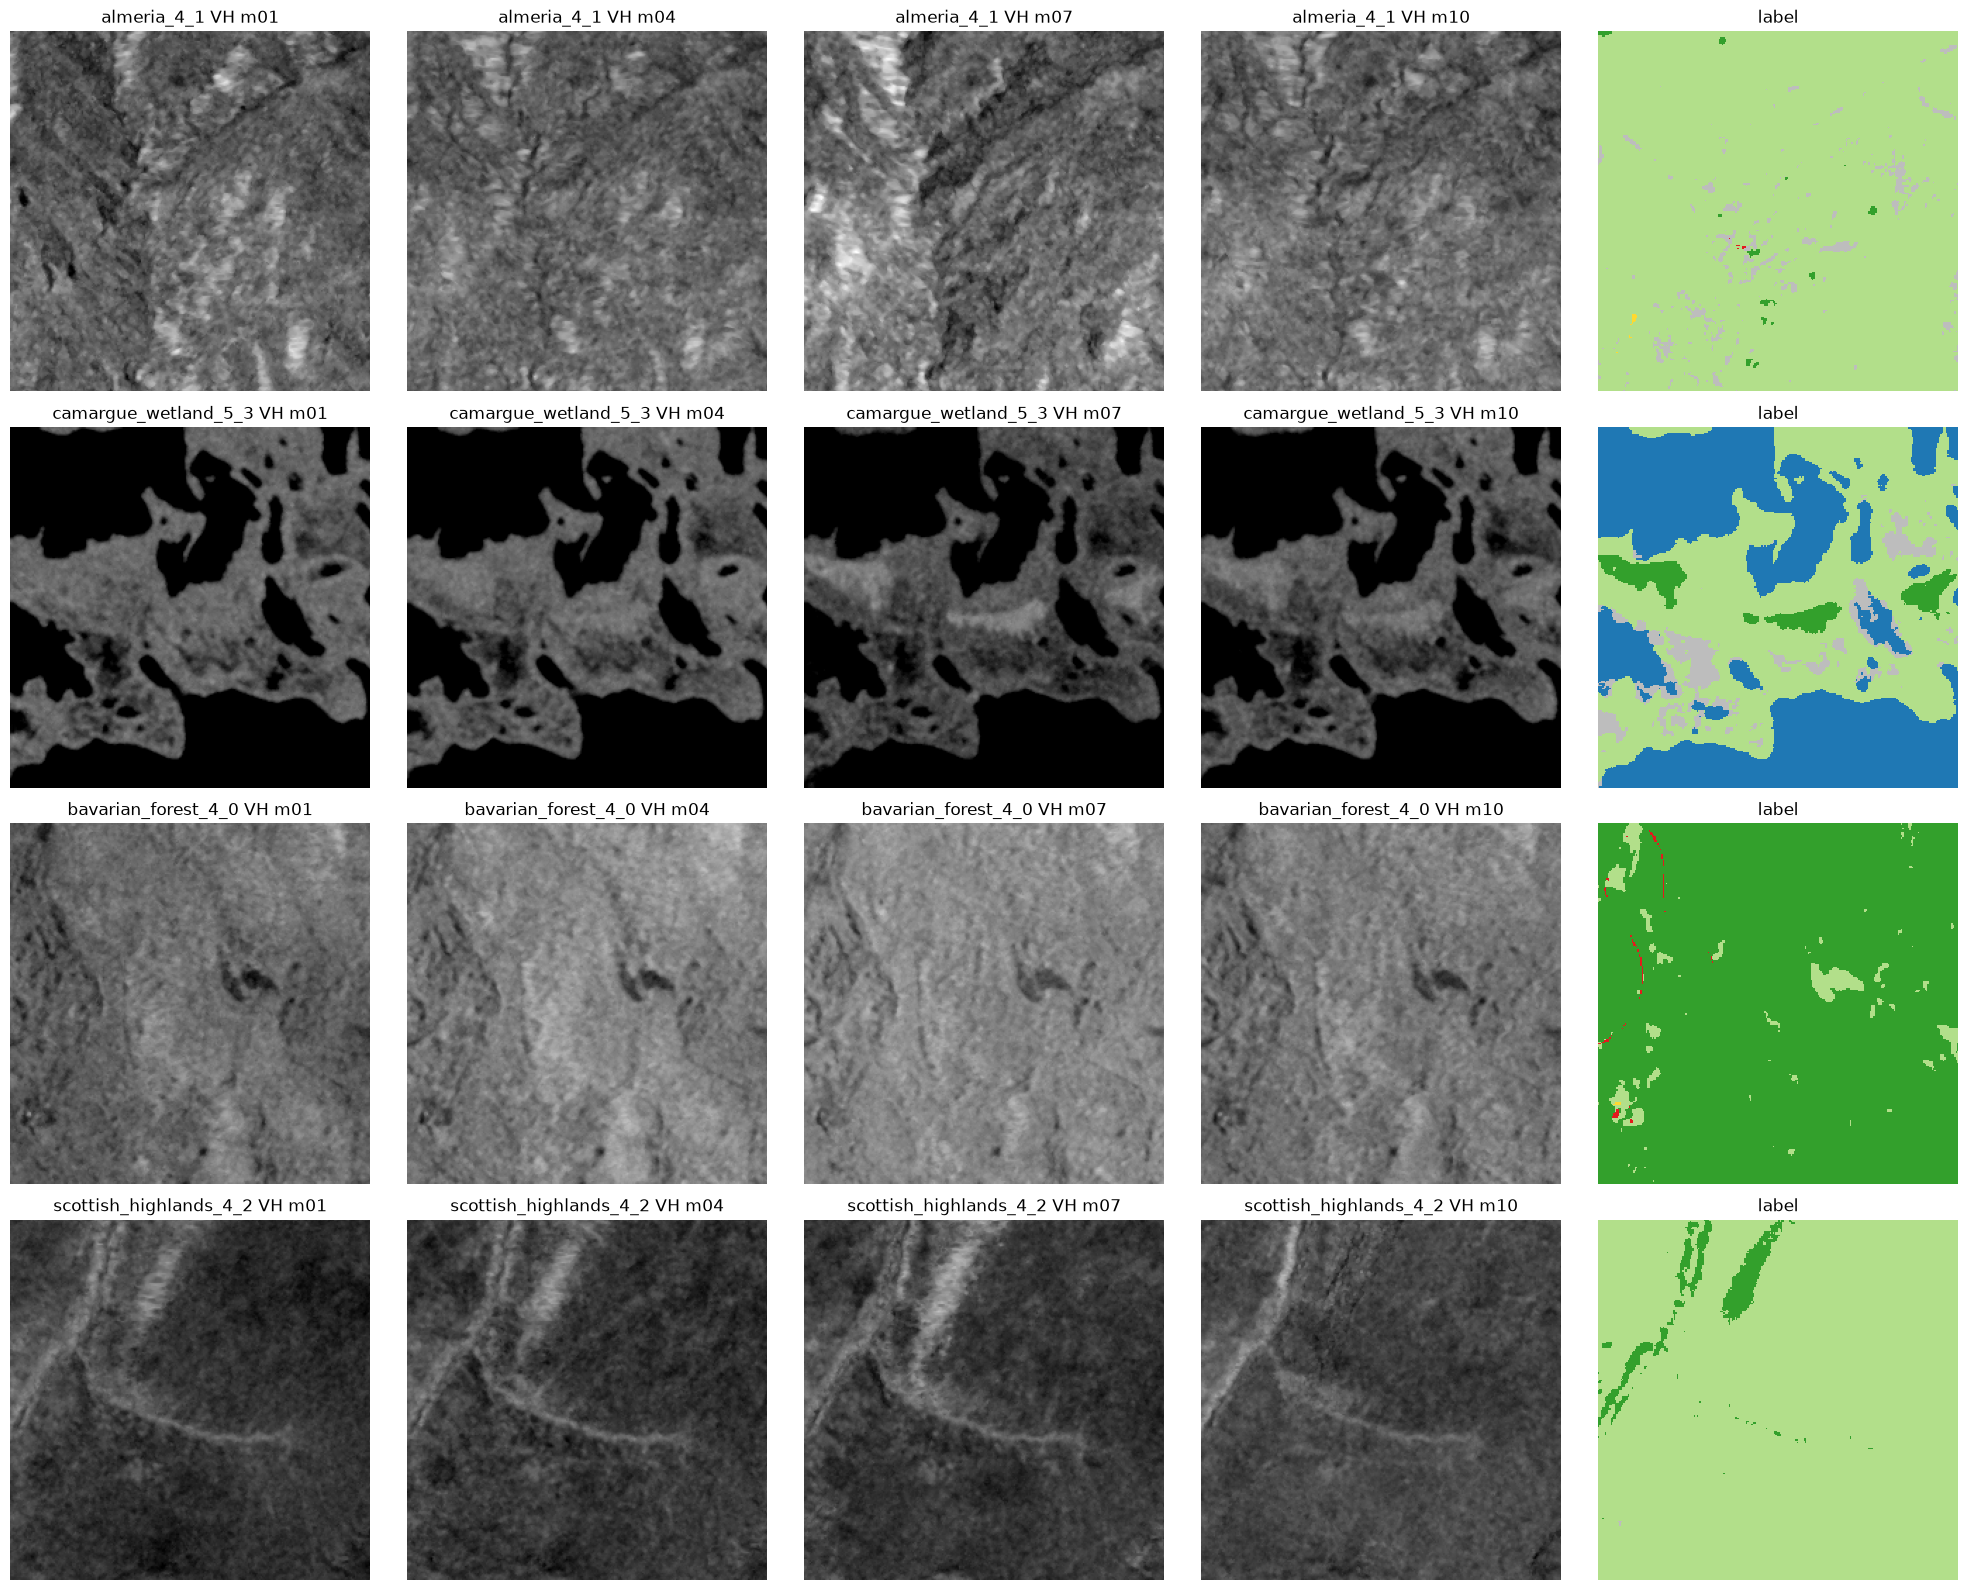

In [11]:
ex = meta[meta.keep].drop_duplicates("patch").sample(4, random_state=1)
fig, ax = plt.subplots(4, 5, figsize=(20, 16))
for row, (_, e) in enumerate(ex.iterrows()):
    for col, m in enumerate(C.TRAIN_MONTHS):
        p = DATA_DIR / f"{e.patch}_m{m:02d}.npy"
        if p.exists():
            ax[row, col].imshow(np.load(p)[1] / C.INT16_SCALE, cmap="gray", vmin=-25, vmax=-5)
        ax[row, col].set_title(f"{e.patch} VH m{m:02d}")
    ax[row, 4].imshow(np.load(DATA_DIR / e.label_path), cmap=CMAP, vmin=0, vmax=C.NUM_CLASSES - 1, interpolation="nearest")
    ax[row, 4].set_title("label")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 10. Package the dataset (for the submission download link)

In [12]:
import shutil
shutil.make_archive(str(ROOT / "s1_lulc_dataset"), "zip", root_dir=ROOT / "data")
print(round(os.path.getsize(ROOT / "s1_lulc_dataset.zip") / 1e9, 2), "GB")

0.86 GB
